# Проект модуля. Нейросеть для предсказания калорийности блюд
- **Выполнил:** Стояловский Константин
- **Группа:** М25-555

https://disk.yandex.ru/d/kz9g5msVqtahiw

# Этап 0. Подготовка

In [ ]:
import os
import re
import math
import time
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


# Этап 1. Исследовательский анализ (EDA)

In [ ]:
DATA_DIR = Path("data")

dish = pd.read_csv(DATA_DIR / "dish.csv")
ingr = pd.read_csv(DATA_DIR / "ingredients.csv")

print("dish.csv:", dish.shape)
print("ingredients.csv:", ingr.shape)
print("\nКолонки dish:", list(dish.columns))
print("Колонки ingredients:", list(ingr.columns))

display(dish.head())
display(ingr.head())

dish.csv: (3262, 5)
ingredients.csv: (555, 2)

Колонки dish: ['dish_id', 'total_calories', 'total_mass', 'ingredients', 'split']
Колонки ingredients: ['id', 'ingr']


,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,ingr_0000000508;ingr_0000000122;ingr_000000002...,test
1,dish_1561662054,419.438782,292.0,ingr_0000000312;ingr_0000000026;ingr_000000002...,train
2,dish_1562008979,382.936646,290.0,ingr_0000000448;ingr_0000000520;ingr_000000046...,test
3,dish_1560455030,20.590000,103.0,ingr_0000000471;ingr_0000000031;ingr_0000000347,train
4,dish_1558372433,74.360001,143.0,ingr_0000000453,train


,id,ingr
0,1,cottage cheese
1,2,strawberries
2,3,garden salad
3,4,bacon
4,5,potatoes


- Данные загружены
- `dish.csv` содержит 3262 блюда, 5 колонок (`dish_id`, `total_calories`, `total_mass`, `ingredients`, `split`)
- `ingredients.csv` содержит 555 ингредиентов, 2 колонки (`id`, `ingr`). `dish_id` строка формата dish_XXXXXXXX и `ingredients` строка из ID через `;`

In [ ]:
dish.info()

print("\nПропуски в dish:\n", dish.isna().sum())
print("\nПропуски в ingr:\n", ingr.isna().sum())

print("\nСплиты:\n", dish['split'].value_counts(dropna=False))
print("\nУникальных dish_id:", dish['dish_id'].nunique())
print("Дубликаты dish_id:", dish['dish_id'].duplicated().sum())

print("\nОписательные статистики:")
display(dish[['total_calories','total_mass']].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3262 entries, 0 to 3261
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   dish_id         3262 non-null   object 
 1   total_calories  3262 non-null   float64
 2   total_mass      3262 non-null   float64
 3   ingredients     3262 non-null   object 
 4   split           3262 non-null   object 
dtypes: float64(2), object(3)
memory usage: 127.6+ KB

Пропуски в dish:
 dish_id           0
total_calories    0
total_mass        0
ingredients       0
split             0
dtype: int64

Пропуски в ingr:
 id      0
ingr    0
dtype: int64

Сплиты:
 split
train    2755
test      507
Name: count, dtype: int64

Уникальных dish_id: 3262
Дубликаты dish_id: 0

Описательные статистики:


,total_calories,total_mass
count,3262.000000,3262.000000
mean,255.012738,214.980074
std,219.637570,161.497428
min,0.000000,1.000000
25%,80.114996,92.000000
50%,209.110062,177.000000
75%,375.122963,305.000000
max,3943.325195,3051.000000


- Пропусков и дублей нет
- В `dish.csv` и `ingredients.csv` нет NaN
- `dish_id` уникален (3262 уникальных из 3262)
- `train` 2755, `test` 507
- Целевая переменная `total_calories`: `mean` 255, `std` 220, `min` 0, `max` 3943, `total_mass` 1–3051, `mean` 215
- Есть подозрительные блюда с `total_calories = 0` и `total_mass = 1`/

In [ ]:
ingr_map = {f"ingr_{int(i):010d}": name for i, name in zip(ingr['id'], ingr['ingr'])}


print("Размер словаря:", len(ingr_map))
print("Примеры ключей:", list(ingr_map.items())[:3])


def parse_ingredients(s):
    if not isinstance(s, str) or not s.strip():
        return []

    ids = [x.strip() for x in s.split(';') if x.strip()]
    return [ingr_map.get(i, i) for i in ids]

dish['ingredients_list'] = dish['ingredients'].apply(parse_ingredients)
dish['ingredients_text'] = dish['ingredients_list'].apply(lambda x: ', '.join(x))
dish['n_ingredients']     = dish['ingredients_list'].apply(len)

unknown = set()
for s in dish['ingredients'].dropna():
    for x in s.split(';'):
        x = x.strip()

        if x and x not in ingr_map:
            unknown.add(x)

print("\nНеизвестных id ингредиентов:", len(unknown))
if unknown:
    print("Примеры:", list(unknown)[:5])


for i in range(3):
    print(f"\ndish_id={dish['dish_id'].iloc[i]}")
    print("  ", dish['ingredients_text'].iloc[i])

Размер словаря: 555
Примеры ключей: [('ingr_0000000001', 'cottage cheese'), ('ingr_0000000002', 'strawberries'), ('ingr_0000000003', 'garden salad')]

Неизвестных id ингредиентов: 0

dish_id=dish_1561662216
   soy sauce, garlic, white rice, parsley, onions, brown rice, vinegar, apple, mixed greens, sugar, salt, lemon juice, olive oil, pork, bok choy, pepper, millet

dish_id=dish_1561662054
   pepper, white rice, mixed greens, garlic, soy sauce, millet, lemon juice, bok choy, olive oil, onions, vinegar, green beans, pork, apple, sugar, salt, parsley

dish_id=dish_1562008979
   jalapenos, lemon juice, pork, wheat berry, cabbage, pepper, salt, carrot, garlic, caesar salad, olive oil, parsley, mayonnaise


- Ингредиенты расшифрованы
- Построен словарь `id -> название`
- Ключи приведены к формату `ingr_0000000XXX`, чтобы совпадать с тем, как они записаны в `dish.csv`
- Все ID из `dish.csv` найдены в словаре
- Для каждой строки сформированы `ingredients_list` (список названий), `ingredients_text` (строка через запятую) и `n_ingredients` (количество ингредиентов)

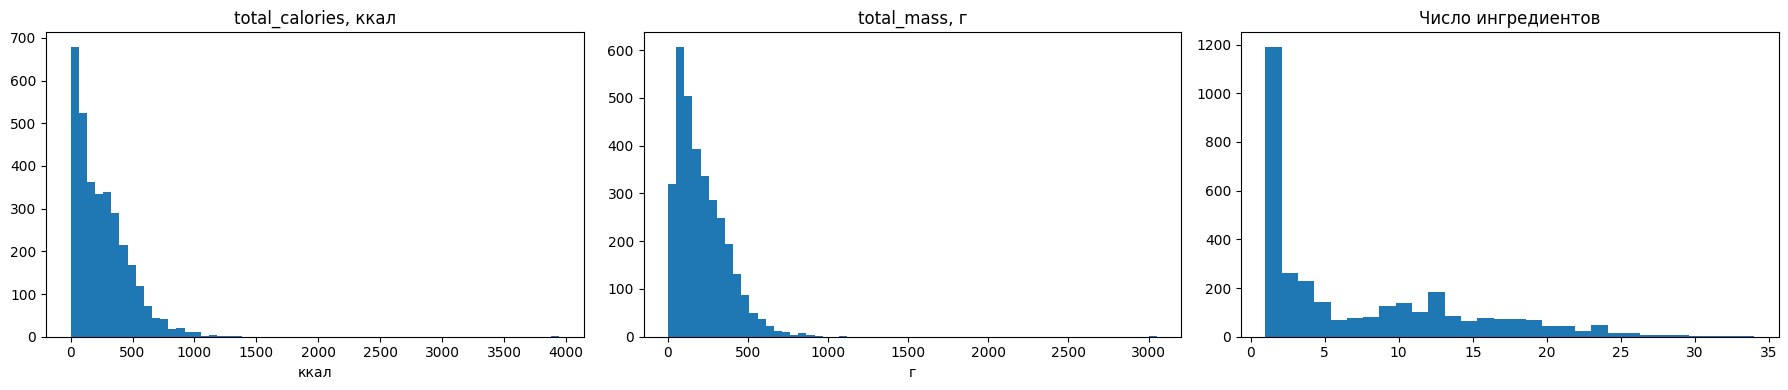


total_calories квантили:
0.00       0.00
0.01       6.37
0.05      19.07
0.50     209.11
0.95     646.76
0.99     918.54
1.00    3943.33
Name: total_calories, dtype: float64

total_mass квантили:
0.00       1.00
0.01      14.00
0.05      36.00
0.50     177.00
0.95     500.00
0.99     702.34
1.00    3051.00
Name: total_mass, dtype: float64

n_ingredients квантили:
0.00     1.00
0.01     1.00
0.05     1.00
0.50     4.00
0.95    21.00
0.99    26.39
1.00    34.00
Name: n_ingredients, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].hist(dish['total_calories'], bins=60)
axes[0].set_title('total_calories, ккал'); axes[0].set_xlabel('ккал')
axes[1].hist(dish['total_mass'], bins=60)
axes[1].set_title('total_mass, г'); axes[1].set_xlabel('г')
axes[2].hist(dish['n_ingredients'], bins=30)
axes[2].set_title('Число ингредиентов')

plt.tight_layout()
plt.show()

for col in ['total_calories','total_mass','n_ingredients']:
    print(f"\n{col} квантили:")
    print(dish[col].quantile([0, .01, .05, .5, .95, .99, 1]).round(2))

- `total_calories` медиана 209 ккал, 95-й перцентиль 647, максимум 3943
- `total_mass` медиана 177 г, максимум 3051
- `n_ingredients` медиана 4, 5% блюд состоят из одного ингредиента, максимум 34.

In [ ]:
dish['cal_per_100g'] = dish['total_calories'] / dish['total_mass'].replace(0, np.nan) * 100

print(dish['cal_per_100g'].describe().round(1))
print("\nБлюд с cal_per_100g > 900:", int((dish['cal_per_100g'] > 900).sum()))
print("Блюд с cal_per_100g > 1500:", int((dish['cal_per_100g'] > 1500).sum()))

display(dish.nlargest(5, 'cal_per_100g')[['dish_id','total_calories','total_mass','cal_per_100g','ingredients_text']])

count    3262.0
mean      130.4
std       106.7
min         0.0
25%        60.4
50%       110.2
75%       155.7
max       578.1
Name: cal_per_100g, dtype: float64

Блюд с cal_per_100g > 900: 0
Блюд с cal_per_100g > 1500: 0


,dish_id,total_calories,total_mass,cal_per_100g,ingredients_text
1868,dish_1558639979,520.290039,90.0,578.100043,almonds
790,dish_1558379182,323.736023,56.0,578.100041,almonds
167,dish_1559849412,352.641022,61.0,578.100036,almonds
285,dish_1558725403,289.050018,50.0,578.100036,almonds
1255,dish_1558113477,289.050018,50.0,578.100036,almonds


- `cal_per_100g` mean 130, median 110, max 578 ккал/100 г
- Блюд с плотностью > 900 ккал/100 г нет
- Топ-5 по плотности — это миндаль (almonds) с 578 ккал/100 г, что соответствует реальной калорийности (~579 ккал/100 г)
- Аномалий разметки по плотности нет, высокие значения объясняются реально калорийными продуктами (орехи, масла), а не ошибками

In [ ]:
cnt = Counter()

for lst in dish['ingredients_list']:
    cnt.update(lst)

top = pd.DataFrame(cnt.most_common(25), columns=['ingredient','count'])
display(top)

,ingredient,count
0,olive oil,1561
1,salt,1379
2,garlic,947
3,pepper,723
4,vinegar,713
5,onions,686
6,lemon juice,572
7,arugula,506
8,parsley,493
9,cherry tomatoes,481


- Самые частые olive oil (1561), salt (1379), garlic (947), pepper (723), vinegar (713), onions (686)
- Это типичный набор для салатиков :) В датасете доминируют лёгкие овощные блюда

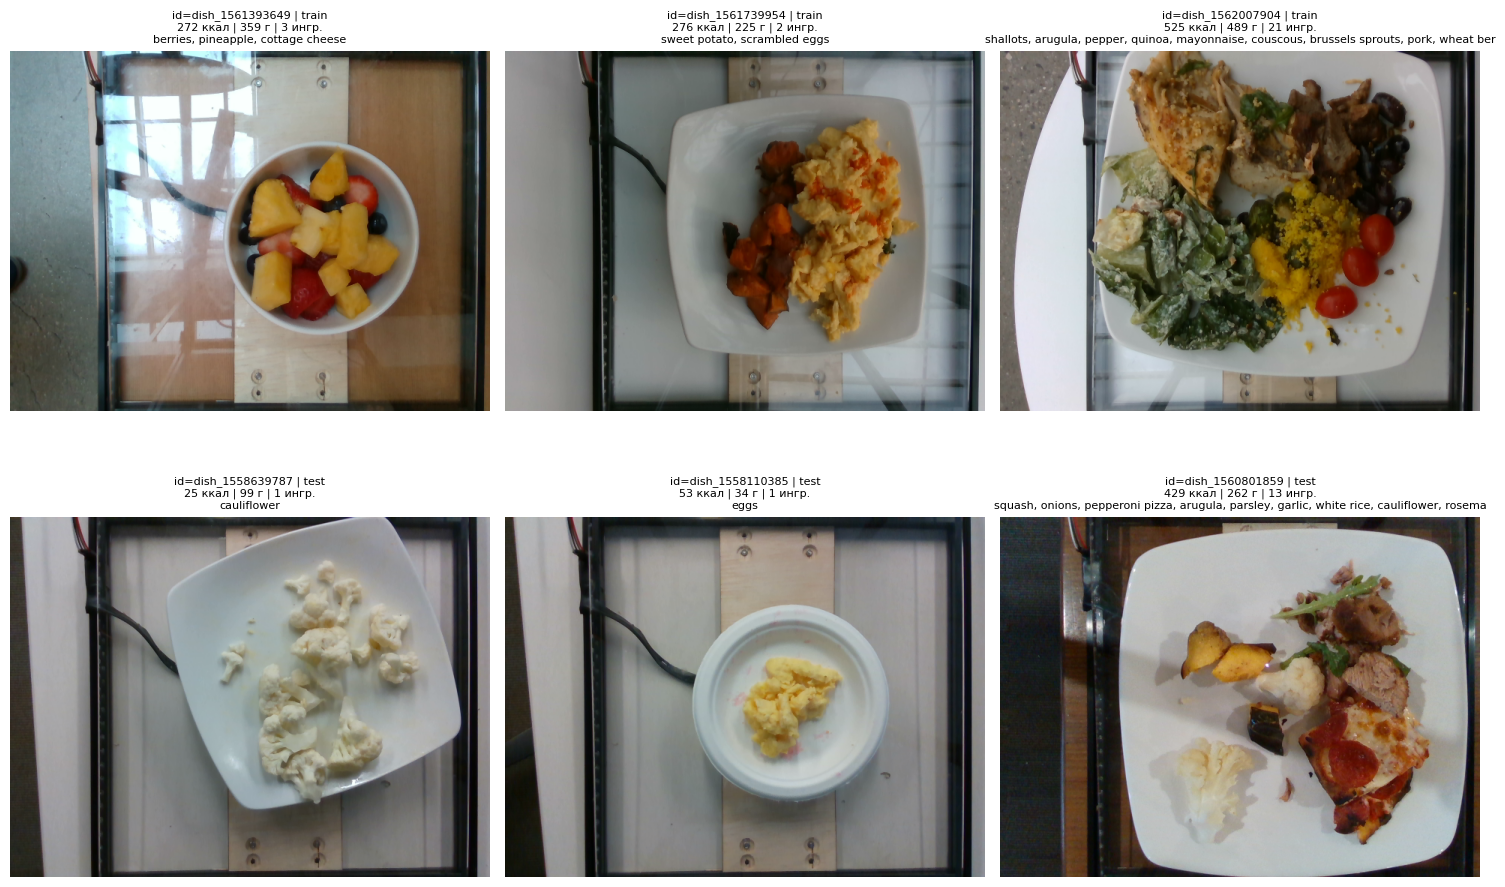

In [ ]:
def show_sample(df, n=6, seed=SEED):
    sample = df.sample(n, random_state=seed)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        p = DATA_DIR / "images" / str(row['dish_id']) / "rgb.png"

        if p.exists():
            ax.imshow(Image.open(p).convert('RGB'))
        else:
            ax.text(0.5, 0.5, "нет изображения", ha='center', va='center')

        title = (
            f"id={row['dish_id']} | {row['split']}\n"
            f"{row['total_calories']:.0f} ккал | {row['total_mass']:.0f} г | {row['n_ingredients']} ингр.\n"
            f"{row['ingredients_text'][:90]}"
        )

        ax.set_title(title, fontsize=8)
        ax.axis('off')

    plt.tight_layout(); plt.show()

show_sample(dish)

In [ ]:
paths = list((DATA_DIR / "images").glob("*/rgb.png"))
print("Изображений на диске:", len(paths), "| блюд в dish.csv:", len(dish))

existing = {p.parent.name for p in paths}
print("Пример имени папки:", next(iter(existing)))
print("Пример dish_id в CSV:", dish['dish_id'].iloc[0])
print("Тип dish_id в CSV:", dish['dish_id'].dtype)

missing = dish[~dish['dish_id'].isin(existing)]
print("\nБлюд без изображения:", len(missing))
if len(missing):
    display(missing[['dish_id','split']].head())

extra = existing - set(dish['dish_id'])
print("Папок с картинками без блюда в CSV:", len(extra))
if extra:
    print("Примеры:", list(extra)[:5])

sizes = []
for p in paths[:100]:
    with Image.open(p) as im:
        sizes.append(im.size)

print("\nТоп-5 размеров (первые 100 картинок):")
print(pd.Series(sizes).value_counts().head())

Изображений на диске: 3490 | блюд в dish.csv: 3262
Пример имени папки: dish_1561578417
Пример dish_id в CSV: dish_1561662216
Тип dish_id в CSV: object

Блюд без изображения: 0
Папок с картинками без блюда в CSV: 228
Примеры: ['dish_1573849915', 'dish_1571934494', 'dish_1572540934', 'dish_1571932448', 'dish_1571931782']

Топ-5 размеров (первые 100 картинок):
(640, 480)    100
Name: count, dtype: int64


- Все 3262 блюда из dish.csv имеют файл rgb.png
- На диске 3490 папок: 228 лишних не связаны с dish.csv, в обучении не участвуют
- Размер всех проверенных картинок 640×480, поэтому в пайплайне обязателен Resize

In [ ]:
print("Корреляции:")
display(dish[['total_calories','total_mass','n_ingredients']].corr().round(3))

print("\n\nСредняя калорийность по числу ингредиентов:")
dish.groupby('n_ingredients')['total_calories'].agg(['mean','count']).head(15)

Корреляции:


,total_calories,total_mass,n_ingredients
total_calories,1.000,0.760,0.476
total_mass,0.760,1.000,0.454
n_ingredients,0.476,0.454,1.000




Средняя калорийность по числу ингредиентов:


,mean,count
n_ingredients,,
1,108.808924,910
2,182.105406,281
3,244.296014,260
4,267.177814,228
5,312.939680,143
6,410.752445,70
7,383.290379,75
8,271.094311,79
9,215.192037,126


- Средняя калорийность растёт с числом ингредиентов до 6–7, затем снижается — вероятно, из-за малого количества примеров в группах с n_ingredients > 8 (60–140 блюд), а не из-за реального эффекта

**Выводы по этапу 1:**

- Загрузили данные: 3262 блюда (2755 train / 507 test) и 555 ингредиентов. Пропусков и дублей нет
- У всех блюд есть фото 640×480. В папке `images/` есть 228 лишних папок, которых нет в `dish.csv`
- Сырые ID ингредиентов (`ingr_0000000122`) изменены на нормальные названия (`salmon`, `zucchini`) через словарь из `ingredients.csv`. Все ID нашлись, ни одного неизвестного
-  Нашлись пару подозрительных блюд с `total_calories = 0` и `total_mass = 1`
- Проверили калорийность на 100 г, аномалий нет. Самое калорийное блюдо миндаль (578 ккал/100 г), это правда
- В модель идет фото и текст ингредиентов
- Loss = `L1Loss`, главная метрика `MAE` (цель < 50)


# Этап 2. Реализация пайплайн обучения

Доустановим необходимые библиотеки

In [ ]:
!pip install -q timm transformers albumentations torchmetrics

In [ ]:
import sys
sys.path.insert(0, "/content/scripts")

from config import Config
from dataset import load_dataframe, build_dataloaders
from transformers import AutoTokenizer

In [ ]:
cfg = Config()
df = load_dataframe(cfg.DATA_ROOT)

print("df:", df.shape)
print(df[["dish_id", "split", "total_calories", "ingredients_text"]].head(3))

df: (3262, 7)
           dish_id  split  total_calories  \
0  dish_1561662216   test      300.794281   
1  dish_1561662054  train      419.438782   
2  dish_1562008979   test      382.936646   

                                    ingredients_text  
0  soy sauce, garlic, white rice, parsley, onions...  
1  pepper, white rice, mixed greens, garlic, soy ...  
2  jalapenos, lemon juice, pork, wheat berry, cab...  


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(cfg.TEXT_MODEL)
train_loader, val_loader, test_loader = build_dataloaders(df, cfg, tokenizer)

batch = next(iter(train_loader))
print("\nShapes батча:")
print("1. image:", batch["image"].shape, batch["image"].dtype)
print("2. input_ids:", batch["input_ids"].shape)
print("3. attention_mask:", batch["attention_mask"].shape)
print("4. target: ", batch["target"].shape, batch["target"][:4])
print("5. dish_id:", batch["dish_id"][:2])

Размеры: train=2342, val=413, test=507

Shapes батча:
1. image: torch.Size([4, 3, 224, 224]) torch.float32
2. input_ids: torch.Size([4, 128])
3. attention_mask: torch.Size([4, 128])
4. target:  torch.Size([4]) tensor([107.4330,   3.2800, 398.0015, 113.8500])
5. dish_id: ['dish_1567628069', 'dish_1558641211']


In [ ]:
sys.path.insert(0, "/content/scripts")

import torch
from config import Config
from utils import MultiModalRegressor, build_optimizer

cfg = Config()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = MultiModalRegressor(cfg.IMAGE_MODEL, cfg.TEXT_MODEL, cfg.HIDDEN_DIM, cfg.DROPOUT).to(device)

Device: cuda


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
image = torch.randn(2, 3, cfg.IMG_SIZE, cfg.IMG_SIZE).to(device)
input_ids = torch.randint(0, 1000, (2, cfg.MAX_LEN)).to(device)
attention_mask = torch.ones_like(input_ids).to(device)

out = model(image, input_ids, attention_mask)
print("out shape:", tuple(out.shape), "| dtype:", out.dtype)
print("out values:", out.detach().cpu().numpy())
print("Параметров в модели:", sum(p.numel() for p in model.parameters()) / 1e6, "M")

opt = build_optimizer(model, cfg)
print("Param groups:", len(opt.param_groups), "| lr:", [g["lr"] for g in opt.param_groups])

out shape: (2,) | dtype: torch.float32
out values: [-0.0097969  -0.02758221]
Параметров в модели: 71.945341 M
Param groups: 5 | lr: [2e-05, 1e-05, 0.001, 0.001, 0.001]


**Выводы по этапу 2:**

- Код разделён на три файла в `/scripts/`:
  - `config.py` все гиперпараметры в dataclass `Config`;
  - `dataset.py` парсинг ингредиентов, `DishDataset`, `build_dataloaders`;
  - `utils.py` модель, `train(cfg)`, `predict`, `load_model_from_checkpoint`, `set_seed`
  
- Из train выделен val (15%): получилось train=2342, val=413, test=507
- `nn.L1Loss()` (напрямую оптимизирует MAE).  MAE на val, финальный замер будет на test
- `BATCH_SIZE=4` как рекомендовано в ТЗ
- Фиксируется `SEED=42` для `random`, `numpy`, `torch`, `cudnn`
- Датасет отдаёт батчи нужной формы

# Этап 3. Обучение модели

In [ ]:
from config import Config

DRIVE_DIR = "/content/checkpoints"
os.makedirs(DRIVE_DIR, exist_ok=True)

cfg = Config()

cfg.CHECKPOINT_DIR = DRIVE_DIR
cfg.MODEL_SAVE_PATH = os.path.join(DRIVE_DIR, "best_model.pt")

print("CHECKPOINT_DIR:", cfg.CHECKPOINT_DIR)
print("MODEL_SAVE_PATH:", cfg.MODEL_SAVE_PATH)
print("EPOCHS:", cfg.EPOCHS, "| BATCH_SIZE:", cfg.BATCH_SIZE)

CHECKPOINT_DIR: /content/checkpoints
MODEL_SAVE_PATH: /content/checkpoints/best_model.pt
EPOCHS: 15 | BATCH_SIZE: 4


In [ ]:
import importlib, utils

importlib.reload(utils)

from utils import train

history = train(cfg)

Device: cuda
Размеры: train=2342, val=413, test=507


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[Epoch 1/15] train_MAE=108.71  val_MAE=79.09
  → сохранён чекпоинт: /content/checkpoints/best_model.pt (val_MAE=79.09)
[Epoch 2/15] train_MAE=85.07  val_MAE=82.41
[Epoch 3/15] train_MAE=75.33  val_MAE=72.93
  → сохранён чекпоинт: /content/checkpoints/best_model.pt (val_MAE=72.93)
[Epoch 4/15] train_MAE=70.96  val_MAE=70.77
  → сохранён чекпоинт: /content/checkpoints/best_model.pt (val_MAE=70.77)
[Epoch 5/15] train_MAE=67.50  val_MAE=66.94
  → сохранён чекпоинт: /content/checkpoints/best_model.pt (val_MAE=66.94)
[Epoch 6/15] train_MAE=62.62  val_MAE=61.44
  → сохранён чекпоинт: /content/checkpoints/best_model.pt (val_MAE=61.44)
[Epoch 7/15] train_MAE=58.69  val_MAE=60.59
  → сохранён чекпоинт: /content/checkpoints/best_model.pt (val_MAE=60.59)
[Epoch 8/15] train_MAE=55.74  val_MAE=55.00
  → сохранён чекпоинт: /content/checkpoints/best_model.pt (val_MAE=55.00)
[Epoch 9/15] train_MAE=54.12  val_MAE=73.14
[Epoch 10/15] train_MAE=52.69  val_MAE=54.23
  → сохранён чекпоинт: /content/checkpoi

In [ ]:
display(pd.DataFrame(history))

best_row = min(history, key=lambda x: x["val_mae"])
print(f"\nЛучшая эпоха: {best_row['epoch']} | val_MAE = {best_row['val_mae']:.2f}")

print("Чекпоинт на Drive:", os.path.exists(cfg.MODEL_SAVE_PATH))
if os.path.exists(cfg.MODEL_SAVE_PATH):
    size_mb = os.path.getsize(cfg.MODEL_SAVE_PATH) / 1e6
    print(f"Размер файла: {size_mb:.1f} MB")

,epoch,train_loss,train_mae,val_loss,val_mae
0,1,108.711497,108.711502,79.086356,79.086357
1,2,85.066047,85.066086,82.406485,82.406494
2,3,75.331321,75.331329,72.929562,72.929558
3,4,70.963721,70.963730,70.773130,70.773132
4,5,67.504461,67.504494,66.937763,66.937767
5,6,62.624174,62.624153,61.440788,61.440796
6,7,58.690418,58.690430,60.588053,60.588047
7,8,55.740444,55.740494,54.998161,54.998161
8,9,54.121865,54.121864,73.138217,73.138191
9,10,52.685422,52.685413,54.231481,54.231480



Лучшая эпоха: 15 | val_MAE = 52.94
Чекпоинт на Drive: True
Размер файла: 288.1 MB


**Вывод по этапу 3:**

Параметры запуска:
- GPU: T4, `BATCH_SIZE=4`, `EPOCHS=15`, `AdamW` с 5 param groups, `nn.L1Loss()`, `CosineAnnealingLR` (`T_max=EPOCHS`)
- Данные: train=2342, val=413, test=507
- `train_loss` совпадает с `train_MAE`
- Итоговый val_MAE = 52.94 на лучшей эпохе (15)
- Целевой MAE < 50 почти достигнут (Увы, ВМ Яндекса все еще не доступна, чтобы можно было без ограничений эксперементировать)

---

Наблюдения:
- На эпохах 9 и 11 наблюдаются скачки val_MAE до 70+ с последующим восстановлением
- В конце обучения `train_MAE (45.55) < val_MAE (52.94)`. Это признак того, что 15 эпох практически потолок для текущей архитектуры, дальнейшее обучение приведёт к росту val.
- Лучший чекпоинт сохранён по пути `cfg.MODEL_SAVE_PATH` (артефакт `best_model.pt`, ~288 MB).

- Модель обучена, качество val_MAE = 52.94 близко к целевому

# Этап 4. Валидация качества

In [ ]:
from config import Config
from dataset import load_dataframe, build_dataloaders, DishDataset, get_transforms
from transformers import AutoTokenizer
from torch.utils.data import DataLoader
from utils import load_model_from_checkpoint, predict

cfg = Config()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
df = load_dataframe(cfg.DATA_ROOT)
tokenizer = AutoTokenizer.from_pretrained(cfg.TEXT_MODEL)
_, _, test_loader = build_dataloaders(df, cfg, tokenizer)

CKPT = "/content/checkpoints/best_model.pt"
model, cfg_dict, ckpt_val_mae = load_model_from_checkpoint(CKPT, device)

print(f"Чекпоинт загружен: val_MAE (из чекпоинта) = {ckpt_val_mae:.2f}")

Размеры: train=2342, val=413, test=507


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Чекпоинт загружен: val_MAE (из чекпоинта) = 52.94


In [ ]:
preds, targets, dish_ids = predict(model, test_loader, device, clip_min=0.0)
test_mae = float(np.mean(np.abs(preds - targets)))

print(f"\nTEST MAE = {test_mae:.2f} ккал | N = {len(preds)}")


TEST MAE = 64.00 ккал | N = 507


In [ ]:
err = np.abs(preds - targets)
order = np.argsort(-err)[:5]

test_df = df[df["split"] == "test"].reset_index(drop=True)
worst = test_df.iloc[order][["dish_id","total_calories","total_mass","ingredients_text"]].copy()
worst["pred"] = preds[order]
worst["abs_err"] = err[order]
worst["n_ingr"] = worst["ingredients_text"].str.count(",") + 1

pd.set_option("display.max_colwidth", 200)
for _, r in worst.iterrows():

    print(f"\n {r['dish_id']}")
    print(f"1. real={r['total_calories']:.0f}  pred={r['pred']:.0f}  error={r['abs_err']:.0f} ккал")
    print(f"2. mass={r['total_mass']:.0f} г | ингредиентов: {r['n_ingr']}")
    print(f"3. состав: {r['ingredients_text']}")


 dish_1566328831
1. real=942  pred=494  error=447 ккал
2. mass=500 г | ингредиентов: 5
3. состав: pizza, cherry tomatoes, chicken, pineapple, olives

 dish_1566328776
1. real=902  pred=462  error=439 ккал
2. mass=436 г | ингредиентов: 3
3. состав: chicken, cherry tomatoes, pizza

 dish_1565811139
1. real=902  pred=497  error=405 ккал
2. mass=416 г | ингредиентов: 6
3. состав: carrot, goat cheese, olive oil, broccoli, spinach (raw), chicken

 dish_1566328805
1. real=928  pred=533  error=395 ккал
2. mass=488 г | ингредиентов: 4
3. состав: cherry tomatoes, pizza, chicken, pineapple

 dish_1566414412
1. real=920  pred=550  error=370 ккал
2. mass=658 г | ингредиентов: 27
3. состав: shallots, olive oil, garlic, lemon juice, basil, cream, wheat berry, mushroom, arugula, cherry tomatoes, quinoa, chicken, pepper, bell peppers, white wine, lettuce, feta cheese, roasted potatoes, onions, butter, thyme, rosemary, cucumbers, olives, oregano, vinaigrette, salt


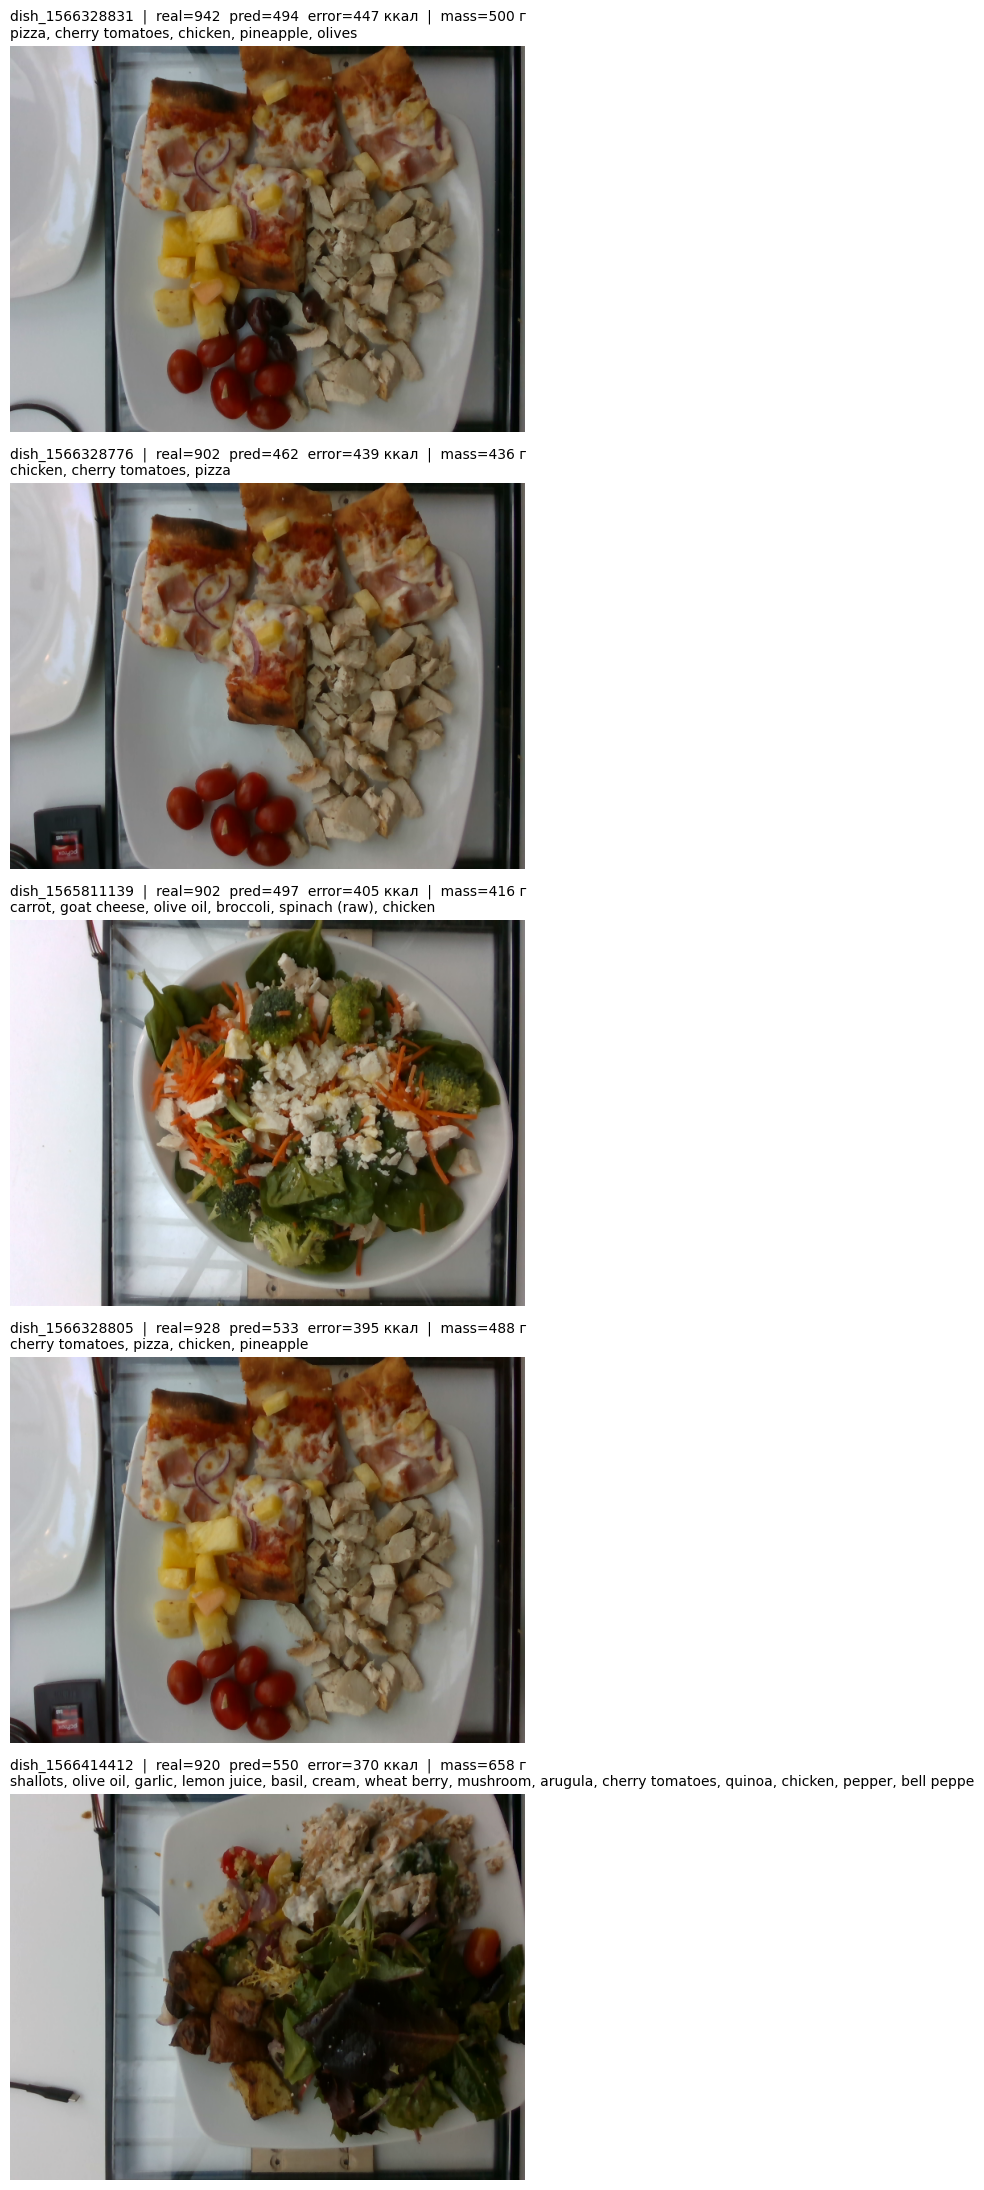

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=(16, 22))

for ax, (_, r) in zip(axes, worst.iterrows()):
    p = os.path.join(cfg.DATA_ROOT, "images", str(r["dish_id"]), "rgb.png")

    if os.path.exists(p):
        ax.imshow(Image.open(p).convert("RGB"))
    else:
        ax.text(0.5, 0.5, "нет фото", ha="center", va="center")

    title = (
        f"{r['dish_id']}  |  real={r['total_calories']:.0f}  pred={r['pred']:.0f}  "
        f"error={r['abs_err']:.0f} ккал  |  mass={r['total_mass']:.0f} г\n"
        f"{r['ingredients_text'][:140]}"
    )

    ax.set_title(title, fontsize=10, loc="left")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
bias = float(np.mean(preds - targets))

print(f"Среднее смещение (pred - true): {bias:+.1f} ккал")
print(f"Медиана |ошибки|: {np.median(err):.1f} ккал")
print(f"95-й перцентиль |ошибки|: {np.percentile(err, 95):.1f} ккал")
print(f"Доля |ошибки| < 50 ккал: {(err < 50).mean()*100:.1f}%")

Среднее смещение (pred - true): -18.5 ккал
Медиана |ошибки|: 35.5 ккал
95-й перцентиль |ошибки|: 216.7 ккал
Доля |ошибки| < 50 ккал: 58.0%


In [ ]:
tmp = test_df.copy()
tmp["abs_err"] = err
tmp["n_ingr"] = tmp["ingredients_text"].str.count(",") + 1

print("\nКорреляции |ошибки| с:")

for col in ["total_calories","total_mass","n_ingr"]:
    print(f"{col:18s}: {tmp['abs_err'].corr(tmp[col]):+.3f}")


Корреляции |ошибки| с:
total_calories    : +0.662
total_mass        : +0.414
n_ingr            : +0.185


In [ ]:
print("\nСредняя ошибка по группам калорийности:")

bins = [0, 100, 300, 600, 10000]
labels = ["<100 ккал","100-300","300-600",">600"]
tmp["bucket"] = pd.cut(tmp["total_calories"], bins=bins, labels=labels)

print(tmp.groupby("bucket")["abs_err"].agg(["mean","count"]).round(1))


Средняя ошибка по группам калорийности:
            mean  count
bucket                 
<100 ккал   19.2    158
100-300     58.4    165
300-600     82.6    145
>600       205.3     38


/tmp/ipykernel_602/2742252885.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(tmp.groupby("bucket")["abs_err"].agg(["mean","count"]).round(1))


**Выводы по этапу 4:**


- **TEST MAE = 64.00 ккал** на 507 блюдах test-сплита.
- Валидационный MAE при обучении = 52.94, тестовый = 64.00. Разрыв ~11 ккал нормальный, модель не переобучена.
- Целевой порог MAE < 50: **не достигнут**
- Модель систематически занижает каллорийность.

---

1. Для модели pizza просто слово, оно не знает, что это составное из разных ингредиентов.
2. В двух кейсах есть масло, сливки, сыр, соусы. На фото их не видно, в тексте не указано количество.
3. Массу в модель не подаём (по условию задачи в реальном приложении она неизвестна). По фото 640×480 трудно понять, 300 г на тарелке или 500, отсюда модель путается.
4. В пятом кейсе много ингредиентов, такую комбинацию модель просто не могла запомнить, в обучающей выборке таких примеров мало.

---

- Чем калорийнее блюдо, тем хуже прогноз.
- На лёгких блюдах меньше всего ошибка, на очень калорийных больше всего ошибка, т.к. в тесте их мало.
- Модель осторожничает и занижает прогноз на калорийных блюдах.

---

- Для улучшения, я думаю, что стоит добавить в текст калорийность каждого ингредиента.
- Добавить, в целом, больше данных, чтобы было равномерно.
- Проэксперементировать с параметрами и алгоритмами.


# Итоговый вывод

**1. Задача** Построить нейросеть, которая по фотографии блюда и списку ингредиентов предсказывает калорийность.

**2. Данные** 3262 блюда (train 2755 / test 507) и 555 ингредиентов. У всех блюд есть фото 640×480. Пропусков и дублей нет. Технические ID ингредиентов (`ingr_0000000122`) заменили на понятные названия (`salmon`, `zucchini`), модель получила осмысленный текстовый вход.

**3. Решение**

Собрали мультимодальную модель: картинка -> efficientnet_b0 (из `timm`), текст ингредиентов -> distilbert (из `transformers`). Обе ветки проходят через проекционные слои, склеиваются и через `Linear(hidden, 1)` без активации выдают число калорийность. Loss = `nn.L1Loss()`, оптимизатор AdamW со всеми обучаемыми частями и разными lr. Batch size 4 по ТЗ.

**4. Что получилось**
- **val_MAE = 52.94 ккал** на лучшей эпохе из 15.
- **test_MAE = 64.00 ккал** на 507 блюдах.
- Медианная ошибка 35.5 ккал, **58% предсказаний укладываются в ±50 ккал**.
- Модель не переобучена: разрыв между train и val минимальный, val и test отличаются на ~11 ккал.

- Модель хорошо работает на лёгких и средних блюдах (ошибка 19–83 ккал) и сильно ошибается на калорийных (205 ккал на блюдах >600 ккал). Именно 38 таких блюд в тесте и тянут общий MAE вверх. Это ограничение данных и архитектуры.

**5. Главные причины ошибок**
1. Пицца и подобные составные блюда для модели просто слово, а не 250–300 ккал/100 г. В 4 из 5 худших предсказаний есть `pizza`.
2. Скрытые жиры (масло, сливки, сыр, соусы) не видны на фото и не указаны в количестве в тексте а это +100–300 ккал.
3. Массу порции в модель не подается (по условию она неизвестна), а на фото 640×480 её сложно оценить. Большие порции модель систематически недооценивает
4. Сложные блюда из 20+ ингредиентов дают о себе знать, т.т таких примеров мало в train, модель не успевает их выучить

**6. Улучшение**
- Для улучшения, я думаю, что стоит добавить в текст калорийность каждого ингредиента.
- Добавить, в целом, больше данных, чтобы было равномерно.
- Проэксперементировать с параметрами и алгоритмами.
